# 03 Job categories

The dataset contains job titles but no job-function category. This notebook creates one primary category for each job from its title and checks how reliable those categories are before they are used in the analysis.

| Field | Value |
|---|---|
| **Purpose** | Give every job one job-function category, and measure how often that category is right |
| **Assignment requirement** | Foundation for Task 2 (emerging categories), Task 3 (high-demand categories), Task 5 (recommendations) and the dashboard |
| **Inputs** | `job_categories.parquet`, `category_summary.csv`, `classifier_report.json`, `classifier_proxy_by_threshold.csv`, `classifier_proxy_by_category.csv`, `label_evaluation_*.csv`, `jobs_clean.parquet` |
| **Outputs** | None; the categories themselves are built by the pipeline (`categorize` and `evaluate` steps) |
| **Build identity** | Printed by the first code cell |

In [1]:
from job_market.notebook import start

project = start()

RUN_ID: 20261011T132714Z-e537465460
Source: data/raw/all_upwork_jobs_2024-02-07-2024-03-24.csv (244,828 rows)
Taxonomy version: 1.0
Verified outputs: 54 file(s), all hashes match
Environment: matches environment.yml


In [2]:
%matplotlib inline
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from job_market.categorize import categorize_title, category_text
from job_market.taxonomy import CATEGORIES, OTHER

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)

categories = project.read_parquet("job_categories.parquet")
jobs = project.read_parquet("jobs_clean.parquet", columns=["row_id", "title_clean", "valid_job_record"])
data = categories.merge(jobs, on="row_id", validate="one_to_one")
valid = data[data["valid_job_record"]].copy()
for column in ("primary_category", "category_method", "classifier_category"):
    valid[column] = valid[column].astype(str)       # plain text: same tables in every pandas version

with open(project.processed("classifier_report.json"), encoding="utf-8") as handle:
    classifier = json.load(handle)
proxy_threshold = project.read_csv("classifier_proxy_by_threshold.csv")
proxy_category = project.read_csv("classifier_proxy_by_category.csv")
summary = project.read_csv("label_evaluation_summary.csv")
by_category = project.read_csv("label_evaluation_by_category.csv")
confusion = project.read_csv("label_evaluation_confusion.csv")
items = project.read_csv("label_evaluation_items.csv")
settings = project.settings.section("categorize")

NAMES = {key: name for key, (name, _) in CATEGORIES.items()}

# Chart style shared with Notebooks 01 and 02.
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#b8b6b0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10, "legend.frameon": False,
})
print(f"{len(valid):,} valid jobs; taxonomy {categories['taxonomy_version'].iloc[0]}, "
      f"categorizer {categories['categorizer_version'].iloc[0]}")

244,827 valid jobs; taxonomy 1.0, categorizer 1.0


## 1. Category structure

A category represents the type of work in the job title, not the client's industry. For example, a virtual assistant working for a real-estate agency belongs to Admin & Virtual Assistance, while real estate stays separate as an industry tag.

The system uses 22 job functions plus Other / Unclear. Version 1.0 of this category list stays fixed before labelling starts, so the human labels and categorisation rules use the same definitions. Detailed rules, examples and tie-breaks are stored in `docs/labelling_guide.md`.

In [3]:
pd.DataFrame([(key, name, definition) for key, (name, definition) in CATEGORIES.items()],
             columns=["id", "category", "covers"]).set_index("id")

,category,covers
id,,
web_development,Web Development,"build or fix websites and web apps (WordPress, Shopify setup, landing pages,..."
mobile_development,Mobile Development,"build or fix phone/tablet apps (iOS, Android, Flutter, React Native)"
software_it,Software & IT,"non-web programming, scripts, automation, scraping, APIs, games, blockchain,..."
ai_ml,AI & Machine Learning,"AI is the core of the work: chatbots, LLM/GPT apps, ML models, computer vision"
data_analytics,Data & Analytics,"analyse and present data: Excel models, Power BI, dashboards, statistics"
design_creative,Design & Creative,"static visuals: logos, branding, UI/UX mock-ups, illustration, thumbnails, 3..."
video_animation,Video & Animation,"moving images: video editing, filming, animation, motion graphics, UGC video..."
photography,Photography,photo shoots and photo editing/retouching
writing_content,Writing & Content,"original text: articles, copywriting, scripts, ghostwriting, proofreading"


### Category rules

- Each job has one primary category so category shares add up to 100%. Other relevant matches can be stored as secondary categories.
- If a title clearly contains two separate tasks with no priority between them, the primary category is Other / Unclear and both tasks remain as secondary categories.
- Industry tags such as real estate, healthcare or e-commerce stay separate from job-function categories and do not affect category shares.

## 2. How a title gets a category

The categorisation rules use a normalised copy of the cleaned title for matching. Text is converted to lowercase, technical terms such as C++, .NET and e-commerce are protected, punctuation is removed and simple plural forms are normalised. These changes are used only for category matching. `title_clean` stays unchanged.

In [4]:
examples = ["C++ Developer for trading bot", "UI/UX Designers needed", "E-commerce Videos for TikTok", "Node.js / Next.js app"]
pd.DataFrame({"title": examples, "matching text": [category_text(t) for t in examples]})

,title,matching text
0,C++ Developer for trading bot,cpp developer for trading bot
1,UI/UX Designers needed,ui ux designer needed
2,E-commerce Videos for TikTok,ecommerce video for tiktok
3,Node.js / Next.js app,nodejs nextjs app


- The category score comes from matched patterns. A specific phrase has a weight of 3, a clear category word has a weight of 2, and a more general word has a weight of 1. A category needs at least 2 points before it can be selected, so one vague word cannot decide the category by itself.
- If more than one category qualifies, tie-break rules use the title context to choose the primary category. For example, mobile takes priority over web when the title clearly describes mobile-app work.
- If a title clearly contains two separate tasks with no priority between them, the primary category becomes Other / Unclear and both matches stay as secondary categories. A minor extra task or two technologies describing the same job do not trigger this rule.
- The examples below show which patterns match and which category is selected.

In [5]:
demo = [
    "Shopify Plus Developer", "AI chatbot developer", "Write blog posts using ChatGPT", "Script for an animated explainer video",
    "Recruitment Product Designer", "Recruitment Process Consultant", "Power BI Dashboard", "SaaS Dashboard Developer",
    "Logo and website", "Build a website and make a small logo", "Experienced OnlyFans Chatter", "Mystery Shopper",
]
rows = []
for title in demo:
    result = categorize_title(title)
    rows.append({"title": title, "category": result.category, "method": result.method,
                 "matched": ", ".join(result.matched_terms[:4]), "also": ", ".join(result.secondary[:3])})
pd.DataFrame(rows)

,title,category,method,matched,also
0,Shopify Plus Developer,web_development,rule,"shopify plus, shopify",software_it
1,AI chatbot developer,ai_ml,rule,"chatbot, ai chatbot, ai",software_it
2,Write blog posts using ChatGPT,writing_content,rule,"blog post, write, blog",ai_ml
3,Script for an animated explainer video,writing_content,rule,script,"video_animation, software_it"
4,Recruitment Product Designer,design_creative,rule,"product designer, designer","hr_recruiting, ecommerce_operations"
5,Recruitment Process Consultant,hr_recruiting,rule,recruitment,business_project_management
6,Power BI Dashboard,data_analytics,rule,"powerbi, dashboard",
7,SaaS Dashboard Developer,software_it,rule,"saas, developer",data_analytics
8,Logo and website,other_unclear,two_tasks,"logo, website","design_creative, web_development"
9,Build a website and make a small logo,web_development,rule,website,design_creative


## 3. Rule coverage
Each valid job records how its primary category is assigned. This makes it possible to see whether the result comes from the rules, the classifier or Other / Unclear.

In [6]:
METHOD_LABELS = {
    "rule": "rule decided", "two_tasks": "two tasks -> Other", "tfidf_classifier": "classifier decided",
    "fallback_blocked": "classifier guess blocked -> Other", "below_threshold": "classifier unsure -> Other",
    "no_text": "no title -> Other",
}
methods = valid["category_method"].value_counts().rename("jobs").to_frame()
methods["share_pct"] = (100 * methods["jobs"] / len(valid)).round(2)
methods.index = methods.index.map(METHOD_LABELS)
methods

,jobs,share_pct
category_method,,
rule decided,211925,86.56
classifier unsure -> Other,22912,9.36
two tasks -> Other,6117,2.50
classifier decided,2861,1.17
classifier guess blocked -> Other,1012,0.41


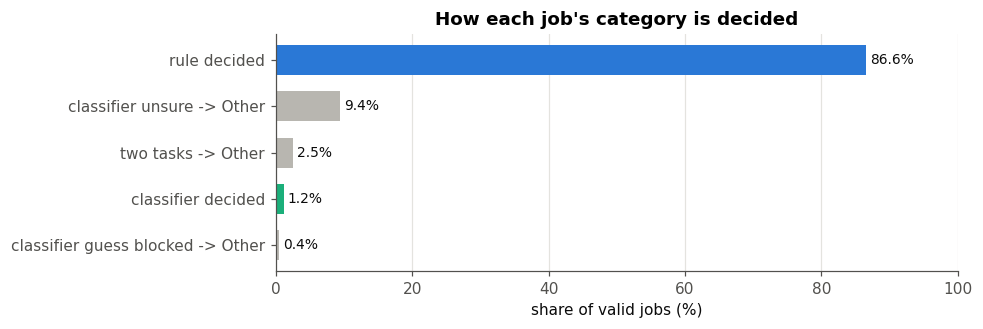

In [7]:
fig, ax = plt.subplots(figsize=(8, 2.8))
order = methods.sort_values("jobs")
colors = [BLUE if "rule decided" == label else AQUA if "classifier decided" == label else GREY for label in order.index]
ax.barh(order.index, order["share_pct"], color=colors, height=0.65)
for y, value in enumerate(order["share_pct"]):
    ax.text(value + 0.6, y, f"{value:.1f}%", va="center", color=INK, fontsize=9)
ax.set_xlabel("share of valid jobs (%)")
ax.set_title("How each job's category is decided")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 100)
plt.show()

In [8]:
rule_jobs = valid[valid["category_method"] == "rule"]
with_secondary = (rule_jobs["secondary_categories"] != "").mean()
print(f"Rule-decided jobs that also match another category: {100 * with_secondary:.0f}%")

Rule-decided jobs that also match another category: 50%


Rules assign the primary category for 87% of jobs. About half of these titles also match a second category, so tie-break rules are important. Around 2.5% of jobs contain two separate tasks and are placed in Other / Unclear. About 11% do not match any rule.

### Unmatched titles
The sample below shows some titles that do not match the category rules.

In [9]:
unmatched = valid[valid["category_method"].isin(["below_threshold", "fallback_blocked", "tfidf_classifier"])]
unmatched.sample(12, random_state=3)[["title_clean", "classifier_category", "classifier_probability", "category_method"]]

,title_clean,classifier_category,classifier_probability,category_method
208425,ONE DAY JOB - Embedded checkout crossmint,software_it,0.243032,below_threshold
180614,Export Local Businesses from Google maps,sales_lead_generation,0.355758,below_threshold
107117,Paid Media Product Feed Exert,digital_marketing,0.438659,below_threshold
23006,PfSense,software_it,0.408606,below_threshold
175363,Redesign trading journal,data_analytics,0.527436,below_threshold
6422,RFP Response,legal,0.219360,below_threshold
240253,List,sales_lead_generation,0.879833,tfidf_classifier
188230,Therapist specializing in CBT,digital_marketing,0.374846,below_threshold
10266,Cryptocurrency Payment Solutions Specialist,software_it,0.517910,below_threshold
143201,Poshmark Lister | Part time (Flexible Hours),customer_service,0.398668,below_threshold


Most unmatched titles are short, vague, in another language, or contain only a brand or tool name. Some are valid jobs for which the rule set has no clear pattern.

## 4. Development labels: 150 titles for rule tuning
The category rules need human examples before they can be finalised. Two separate label sets keep rule tuning and final evaluation apart.

- The development set contains 150 titles: 110 random titles, 20 very short titles and 20 titles containing joined tasks. These titles are used to improve the rules, weights and confidence threshold.
- The blind set contains 350 randomly selected titles. It stays separate from rule tuning and receives one score only after the categorisation system is frozen.

No `title_key` appears in both sets. Each label is based only on the title, with no system prediction visible. An `unsure` field records cases where the category is not clear.

Each label sheet is bound to the raw extract it was drawn from, and to its exact file hash, in `data/labels/label_sources.toml` (decision D-039). The pipeline scores a sheet only when both match.

### Rule refinements
The development titles reveal a few cases where the first rules need clearer handling:

- recruitment plus a clear job role follows the actual job role, while recruitment work itself stays in HR;
- consumer-style testing and survey participation go to Other / Unclear, while software testing stays in Software & IT;
- an app with no clear web or mobile signal goes to Software & IT;
- website artwork stays in Design, while a coded dashboard follows the type of work it represents;
- advertising work stays in Marketing, while building advertising tools belongs to Software & IT;
- specific tools such as OpenSCAD and Apify help separate Engineering from Software.

Agreement on the development set is 83% (125 of 150), compared with 76% (114 of 150) for the first rule set, recorded in D-029. Because these same 150 titles guide the rule changes, this is a development result, not an independent accuracy estimate.

In [10]:
dev = summary[summary["label_set"] == "dev"].set_index(["subset", "system"])
dev[["titles", "correct", "accuracy", "wilson_low", "wilson_high"]]

titles  correct  accuracy  wilson_low  wilson_high
subset              system                                                        
all                 full           150      125    0.8333      0.7655       0.8845
                    rules_only     150      125    0.8333      0.7655       0.8845
labelled_sure       full           123      110    0.8943      0.8275       0.9372
labelled_unsure     full            27       15    0.5556      0.3731       0.7241
decided_by_rule     full           131      119    0.9084      0.8467       0.9468
predicted_not_other full           127      115    0.9055      0.8421       0.9451

## 5. Fallback classifier
- Titles that do not receive a category from the rules are passed to a TF-IDF and logistic regression classifier.
- TF-IDF converts words and short character patterns in the title into numerical features. Logistic regression uses those features to estimate the probability of each category.
- The classifier trains only on high-confidence titles labelled by the rule system. Human development and blind labels are not used for training, so they remain separate for evaluation.
- The words that trigger the original rules are removed from the classifier's training text. This prevents the model from simply learning the same rule words and makes it rely on the remaining title context.
- A grouped test split based on `title_key` is used to check the fallback model and choose its confidence threshold. The same cleaned title cannot appear in both training and test groups.

In [11]:
pd.Series({
    "weak labels (training titles)": classifier["weak_labels"],
    "proxy test titles": classifier["proxy_test_titles"],
    "title keys shared between training and proxy test": classifier["proxy_title_keys_shared_with_training"],
    "proxy titles whose masked text also occurs in training": classifier["proxy_masked_texts_also_in_training"],
}).to_frame("value")

,value
weak labels (training titles),34816
proxy test titles,6958
title keys shared between training and proxy test,0
proxy titles whose masked text also occurs in training,1474


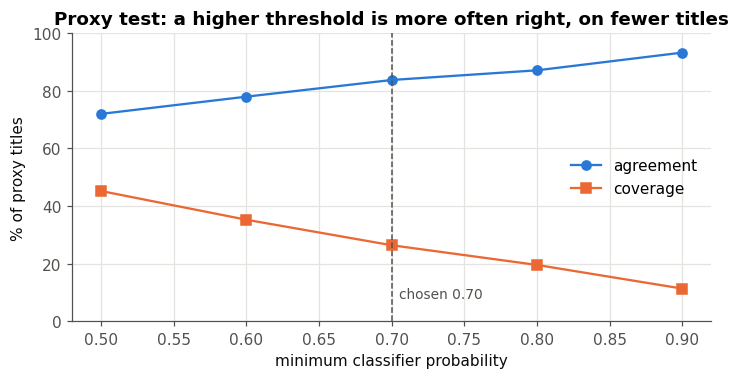

,threshold,predictions,coverage,agreement
0,0.5,3145,0.4520,0.7199
1,0.6,2451,0.3523,0.7797
2,0.7,1835,0.2637,0.8376
3,0.8,1359,0.1953,0.8712
4,0.9,787,0.1131,0.9327


In [12]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(proxy_threshold["threshold"], 100 * proxy_threshold["agreement"], marker="o", color=BLUE, label="agreement")
ax.plot(proxy_threshold["threshold"], 100 * proxy_threshold["coverage"], marker="s", color=ORANGE, label="coverage")
ax.axvline(settings["classifier_threshold"], color=MUTED, ls="--", lw=1)
ax.text(settings["classifier_threshold"] + 0.005, 8, "chosen 0.70", color=MUTED, fontsize=9)
ax.set_xlabel("minimum classifier probability")
ax.set_ylabel("% of proxy titles")
ax.set_ylim(0, 100)
ax.set_title("Proxy test: a higher threshold is more often right, on fewer titles")
ax.legend(loc="center right")
plt.show()
proxy_threshold

Coverage shows how many held-out titles receive a prediction above the confidence threshold. Agreement shows how often those predictions match the rule labels. At a threshold of 0.70, the classifier predicts about a quarter of the titles and agrees with the rule labels on about 84%.

### Category-level reliability
The overall agreement can hide weak performance in individual categories, so the results are also checked separately by predicted category at the 0.70 threshold.

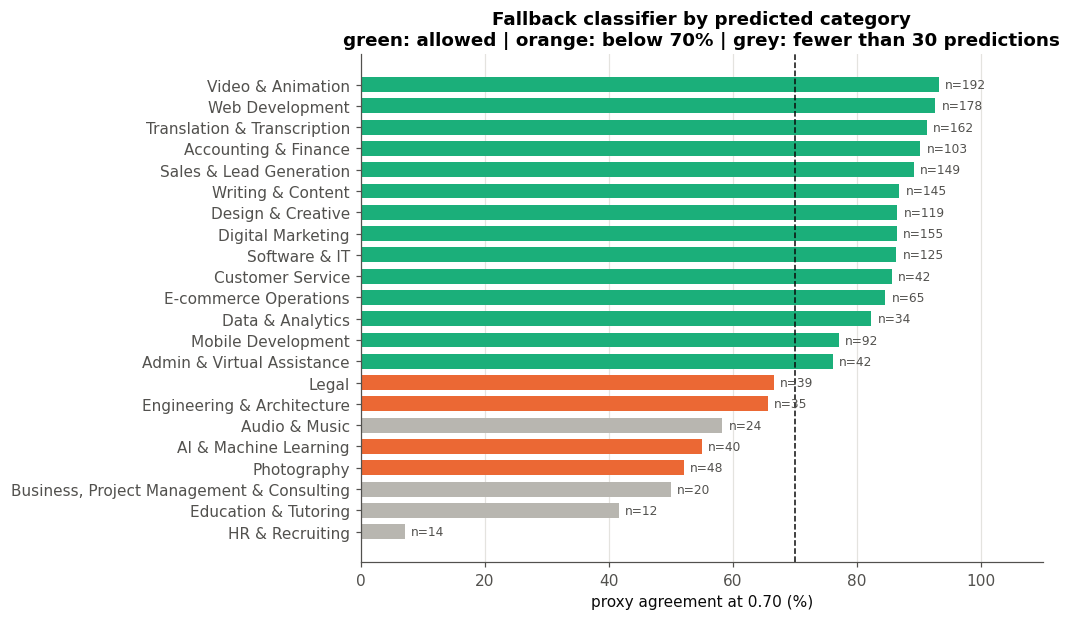

In [13]:
table = proxy_category.sort_values("agreement")
fig, ax = plt.subplots(figsize=(8, 6))
colors = [AQUA if passes else (ORANGE if enough else GREY)
          for passes, enough in zip(table["passes_guard_rule"], table["enough_support"])]
ax.barh(table["predicted_category"].map(NAMES), 100 * table["agreement"], color=colors, height=0.7)
for y, (value, n) in enumerate(zip(table["agreement"], table["predictions"])):
    ax.text(100 * value + 1, y, f"n={n}", va="center", fontsize=8, color=MUTED)
ax.axvline(100 * settings["fallback_min_proxy_agreement"], color=INK, lw=1, ls="--")
ax.set_xlabel("proxy agreement at 0.70 (%)")
ax.set_xlim(0, 110)
ax.set_title("Fallback classifier by predicted category\n"
             "green: allowed | orange: below 70% | grey: fewer than 30 predictions")
ax.grid(axis="y", visible=False)
plt.show()

- At the 0.70 confidence threshold, 14 categories meet the reliability rule. AI & ML, Photography, Engineering and Legal have enough predictions but remain below 70% agreement. HR, Education, Business & Project Management and Audio & Music have too few predictions to judge reliably.
- The fallback classifier can assign a category only when that category has at least 30 proxy predictions and at least 70% agreement. If either condition is not met, the title goes to Other / Unclear. The rule-based system can still assign all 22 categories.

In [14]:
pd.Series({
    "threshold": classifier["classifier_threshold"],
    "proxy predictions at 0.70": classifier["proxy_predictions_at_threshold"],
    "agreement at 0.70": classifier["proxy_agreement_at_threshold"],
    "agreement at 0.70, titles without a masked twin in training": classifier["proxy_agreement_at_threshold_no_twin"],
    "proxy predictions with the guard": classifier["proxy_predictions_with_guard"],
    "agreement with the guard": classifier["proxy_agreement_with_guard"],
    "agreement with the guard, titles without a masked twin": classifier["proxy_agreement_with_guard_no_twin"],
    "this build's proxy test selects the frozen list": classifier["fallback_list_matches_proxy_rule"],
}).to_frame("value")

,value
threshold,0.7
proxy predictions at 0.70,1835
agreement at 0.70,0.8376
"agreement at 0.70, titles without a masked twin in training",0.8463
proxy predictions with the guard,1603
agreement with the guard,0.8802
"agreement with the guard, titles without a masked twin",0.8906
this build's proxy test selects the frozen list,True


- At the 0.70 threshold, the unrestricted fallback agrees with the held-out rule labels on about 84% of its predictions. The category guard raises this to about 88% while reducing coverage by about one eighth.
- A separate check removes titles whose masked text has an identical match in training and gives a similar result. This shows that duplicate-like titles do not drive the score.
- These proxy labels come from the rule system, not from human labels. They are used only to choose the fallback policy and are not treated as category accuracy.

## 6. Freeze before blind evaluation

Before blind evaluation starts, the category system stays fixed:

- category list: version 1.0 with 22 job functions plus Other / Unclear
- category rules, weights and tie-breaks
- TF-IDF and logistic-regression classifier settings
- confidence threshold: 0.70
- 14 categories allowed for fallback prediction
- categorizer version: 1.0
- label provenance: both label sheets bound to this extract (D-039)

The Git tag `categorizer-1.0` marks this fixed version. The separate tag `blind-labels-final` marks the blind-label file before scoring. This keeps rule tuning and blind evaluation separate.

In [15]:
pd.Series({
    "taxonomy version": str(categories["taxonomy_version"].iloc[0]),
    "categorizer version": str(categories["categorizer_version"].iloc[0]),
    "classifier threshold": settings["classifier_threshold"],
    "fallback categories": len(settings["fallback_categories"]),
}).to_frame("value")

,value
taxonomy version,1.0
categorizer version,1.0
classifier threshold,0.7
fallback categories,14


## 7. Category sizes
The chart shows the share of valid jobs in each category. Other / Unclear stays visible because it is part of the category result.

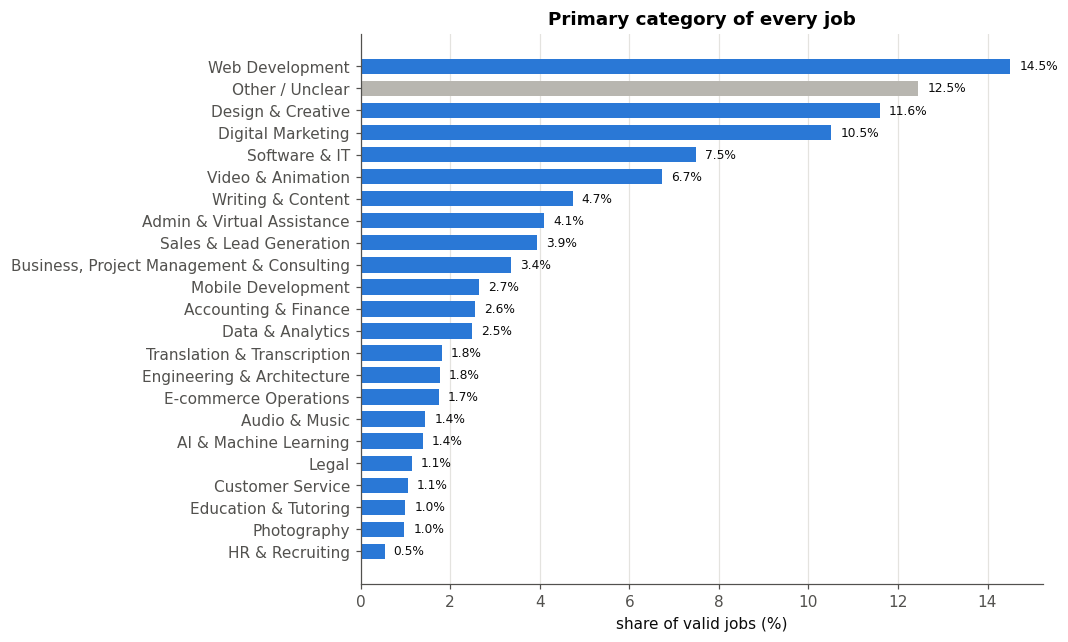

In [16]:
shares = (100 * valid["primary_category"].value_counts(normalize=True)).rename("share_pct").to_frame()
shares["jobs"] = valid["primary_category"].value_counts()
shares.index.name = "category"
fig, ax = plt.subplots(figsize=(8, 6.5))
ordered = shares.sort_values("share_pct")
ax.barh(ordered.index.map(NAMES), ordered["share_pct"],
        color=[GREY if c == OTHER else BLUE for c in ordered.index], height=0.7)
for y, value in enumerate(ordered["share_pct"]):
    ax.text(value + 0.2, y, f"{value:.1f}%", va="center", fontsize=8, color=INK)
ax.set_xlabel("share of valid jobs (%)")
ax.set_title("Primary category of every job")
ax.grid(axis="y", visible=False)
plt.show()

In [17]:
# Blind titles: how many the humans and the system put in each category.
blind_labels = items[items["label_set"] == "blind"]
blind_counts = pd.DataFrame({"human": blind_labels["human"].value_counts(),
                             "predicted": blind_labels["predicted"].value_counts()}).fillna(0).astype(int)
blind_counts["difference"] = blind_counts["predicted"] - blind_counts["human"]
blind_counts.assign(category=blind_counts.index.map(NAMES)).set_index("category").sort_values("difference")

,human,predicted,difference
category,,,
Software & IT,41,25,-16
Design & Creative,48,38,-10
AI & Machine Learning,13,5,-8
Engineering & Architecture,11,6,-5
Admin & Virtual Assistance,13,9,-4
Sales & Lead Generation,16,13,-3
Accounting & Finance,11,8,-3
Audio & Music,7,5,-2
Translation & Transcription,9,7,-2


In [18]:
tags = valid["industry_tags"].str.split("; ").explode()
tags = tags[tags != ""]
print(f"Jobs with at least one industry tag: {100 * (valid['industry_tags'] != '').mean():.1f}%")
tags.value_counts().rename("jobs").to_frame()

Jobs with at least one industry tag: 10.8%


,jobs
industry_tags,
ecommerce,11551
real_estate,3658
healthcare,3616
crypto_web3,3057
finance,2441
education,1541
legal,1200


- Web Development accounts for about 15% of jobs, Design & Creative about 12%, and Digital Marketing about 11%. Together with Software & IT, Video & Animation and Writing & Content, these categories make up more than half of all jobs. Other / Unclear accounts for about 12%.
- On the 350 blind titles, the system predicts fewer Software & IT (25 against 41 human labels), Design & Creative (38 against 48) and AI & Machine Learning (5 against 13) titles. It predicts more Other / Unclear (47 against 22), Web Development (50 against 38) and Data & Analytics (12 against 4).
- These differences suggest that some category shares in the full dataset may be too high or too low. The comparison is based on 350 sampled titles, so it does not measure the exact size of the error across all jobs. This matters when interpreting category trends, especially for AI & Machine Learning.
- E-commerce is the most common industry tag, followed by real estate and healthcare. Industry tags stay separate from job-function categories, so a job can have one primary job category and an additional industry tag.

## 8. Blind evaluation
- The frozen categorisation system is evaluated once on 350 blind human-labelled titles.
- The 95% Wilson interval shows the uncertainty around the agreement estimate from this sample. It is used because the evaluation contains only 350 titles and gives a more suitable interval for a proportion than a simple normal approximation.

In [19]:
evaluate_metrics = project.step_metrics("evaluate")
print(f"Label status in this build: dev {evaluate_metrics['dev_labels']}, blind {evaluate_metrics['blind_labels']}")
blind = summary[summary["label_set"] == "blind"].set_index(["subset", "system"])
blind[["titles", "correct", "accuracy", "wilson_low", "wilson_high"]]

Label status in this build: dev scored, blind scored


titles  correct  accuracy  wilson_low  wilson_high
subset              system                                                        
all                 full           350      241    0.6886      0.6382       0.7348
                    rules_only     350      240    0.6857      0.6353       0.7321
labelled_sure       full           290      221    0.7621      0.7098       0.8075
labelled_unsure     full            60       20    0.3333      0.2273       0.4594
decided_by_rule     full           302      233    0.7715      0.7209       0.8153
predicted_not_other full           303      234    0.7723      0.7218       0.8159

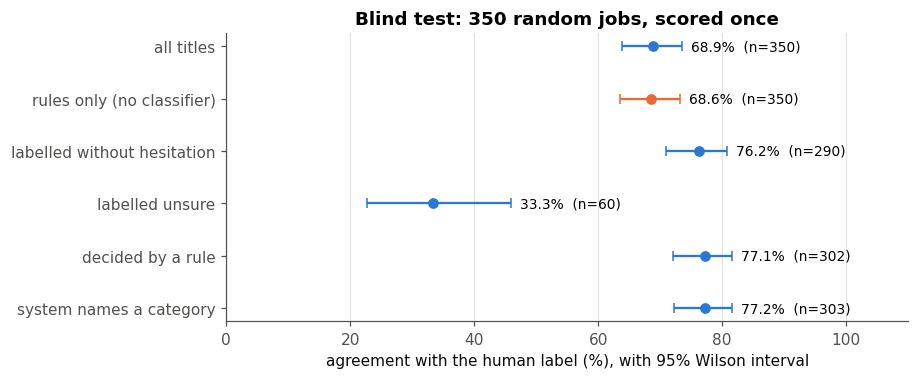

In [20]:
rows = [("all titles", ("all", "full")), ("rules only (no classifier)", ("all", "rules_only")),
        ("labelled without hesitation", ("labelled_sure", "full")), ("labelled unsure", ("labelled_unsure", "full")),
        ("decided by a rule", ("decided_by_rule", "full")), ("system names a category", ("predicted_not_other", "full"))]
fig, ax = plt.subplots(figsize=(8, 3.4))
for y, (label, key) in enumerate(rows[::-1]):
    row = blind.loc[key]
    ax.errorbar(100 * row["accuracy"], y, xerr=[[100 * (row["accuracy"] - row["wilson_low"])],
                                                [100 * (row["wilson_high"] - row["accuracy"])]],
                fmt="o", color=BLUE if key[1] == "full" else ORANGE, capsize=3)
    ax.text(100 * row["wilson_high"] + 1.5, y, f"{100 * row['accuracy']:.1f}%  (n={int(row['titles'])})",
            va="center", fontsize=9)
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([label for label, _ in rows[::-1]])
ax.set_xlim(0, 110)
ax.set_xlabel("agreement with the human label (%), with 95% Wilson interval")
ax.set_title("Blind test: 350 random jobs, scored once")
ax.grid(axis="y", visible=False)
plt.show()

On the 350 blind titles, the category system agrees with the human labels 68.9% of the time, with a 95% interval from 63.8% to 73.5%. This is a result for this extract only.

This is lower than the 83% agreement on the development set because the development titles are used to tune the rules, while the blind titles are kept separate from tuning.

- Agreement is 76.2% for titles labelled without hesitation and 33.3% for titles marked unsure.
- When the system assigns a named category instead of Other / Unclear, agreement is 77.2%.
- Removing the fallback classifier changes overall agreement from 68.9% to 68.6%. Only 1 of the 350 blind titles is decided by the classifier, and that prediction is correct. This is too little evidence to assess the classifier's performance independently. The proxy evaluation in section 5 provides additional evidence, but it is not a substitute for a larger independent human-labelled test.

In [21]:
blind_items = items[items["label_set"] == "blind"]
other_rate = pd.Series({
    "human chose Other (%)": 100 * (blind_items["human"] == OTHER).mean(),
    "system predicted Other (%)": 100 * (blind_items["predicted"] == OTHER).mean(),
}).round(1)
other_rate.to_frame("blind titles")

,blind titles
human chose Other (%),6.3
system predicted Other (%),13.4


### Per-category evaluation
- Precision shows how often a category assigned by the system is correct.
- Recall shows how much of a human-labelled category the system finds.
- F1 score balances precision and recall.
- When a category has no human-labelled titles, recall and F1 are shown as blank because they cannot be meaningfully measured from this sample.
- Categories with fewer than 10 blind examples are marked separately because their scores are based on very small samples and should be interpreted carefully.

In [22]:
per = by_category[by_category["label_set"] == "blind"].copy()
per["name"] = per["category"].map(NAMES)
per["small sample"] = np.where(per["human_titles"] < 10, "yes", "")
shown = per.sort_values("human_titles", ascending=False)[
    ["name", "human_titles", "predicted_titles", "precision", "recall", "f1", "small sample"]].set_index("name")
# Display copy only: recall and F1 are undefined for a category with no human-labelled titles.
shown = shown.astype({"recall": object, "f1": object})
shown.loc[shown["human_titles"] == 0, ["recall", "f1"]] = ""
shown

,human_titles,predicted_titles,precision,recall,f1,small sample
name,,,,,,
Design & Creative,48,38,0.8947,0.7083,0.7907,
Software & IT,41,25,0.7600,0.4634,0.5758,
Web Development,38,50,0.7200,0.9474,0.8182,
Digital Marketing,38,39,0.8462,0.8684,0.8571,
Other / Unclear,22,47,0.1489,0.3182,0.2029,
Writing & Content,20,20,0.7000,0.7,0.7,
Video & Animation,20,21,0.8095,0.85,0.8293,
Sales & Lead Generation,16,13,0.9231,0.75,0.8276,
Admin & Virtual Assistance,13,9,0.6667,0.4615,0.5455,


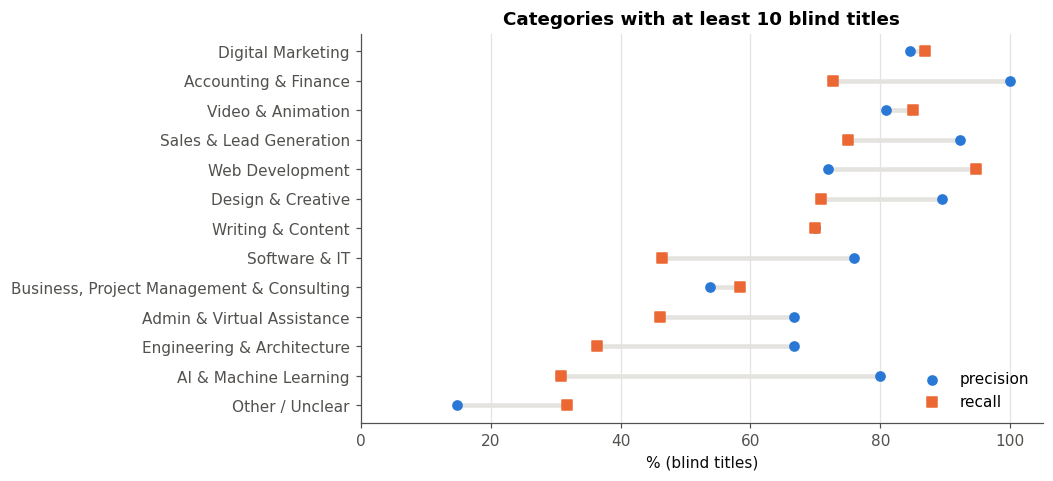

In [23]:
big = per[per["human_titles"] >= 10].sort_values("f1")
fig, ax = plt.subplots(figsize=(8, 4.6))
y = np.arange(len(big))
ax.scatter(100 * big["precision"], y, color=BLUE, label="precision", zorder=3)
ax.scatter(100 * big["recall"], y, color=ORANGE, marker="s", label="recall", zorder=3)
for i, (p, r) in enumerate(zip(big["precision"], big["recall"])):
    ax.plot([100 * min(p, r), 100 * max(p, r)], [i, i], color=GRID, lw=3, zorder=2)
ax.set_yticks(y)
ax.set_yticklabels(big["name"])
ax.set_xlim(0, 105)
ax.set_xlabel("% (blind titles)")
ax.set_title("Categories with at least 10 blind titles")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()

- Digital Marketing, Video & Animation, Web Development, Sales & Lead Generation, Design & Creative, and Accounting & Finance have F1 scores around 0.8.
- Software & IT, AI & ML, Engineering & Architecture, and Admin & Virtual Assistance have low recall, around 31% to 46%. Many human-labelled titles in these categories are classified as Other / Unclear or another category.
- Other / Unclear has low precision because many titles assigned to it have a named category in the human labels. Web Development has high recall but lower precision because some Software & IT titles are classified as Web Development.

### Main category confusions

In [24]:
mistakes = confusion[(confusion["label_set"] == "blind") & (confusion["human"] != confusion["predicted"])]
mistakes.head(10)[["human", "predicted", "titles"]].reset_index(drop=True)

,human,predicted,titles
0,software_it,web_development,8
1,software_it,other_unclear,6
2,engineering_architecture,other_unclear,5
3,admin_virtual_assistance,other_unclear,4
4,ai_ml,other_unclear,4
5,design_creative,other_unclear,3
6,software_it,business_project_management,3
7,software_it,data_analytics,3
8,writing_content,other_unclear,3
9,accounting_finance,other_unclear,2


### Agreement and coverage
A stricter rule score gives fewer category predictions, but the predictions it keeps agree with the human labels more often. The curve shows this trade-off across the blind titles.

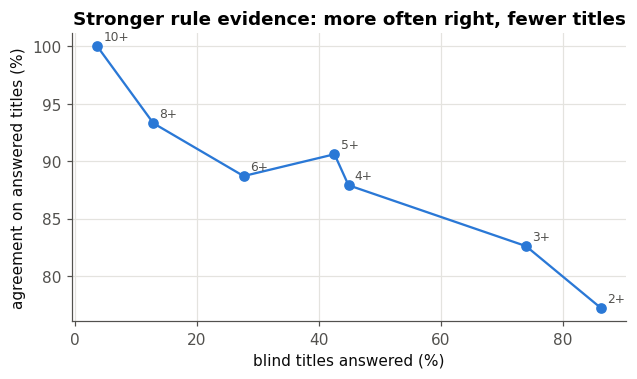

,minimum rule score,coverage_pct,accuracy_pct
0,2,86.3,77.2
1,3,74.0,82.6
2,4,44.9,87.9
3,5,42.6,90.6
4,6,27.7,88.7
5,8,12.9,93.3
6,10,3.7,100.0


In [25]:
decided = blind_items[blind_items["category_method"] == "rule"]
curve = pd.DataFrame([
    {"minimum rule score": s,
     "coverage_pct": 100 * (decided["rule_score"] >= s).sum() / len(blind_items),
     "accuracy_pct": 100 * decided.loc[decided["rule_score"] >= s, "correct"].mean()}
    for s in [2, 3, 4, 5, 6, 8, 10]
]).round(1)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(curve["coverage_pct"], curve["accuracy_pct"], marker="o", color=BLUE)
for _, row in curve.iterrows():
    ax.annotate(f"{int(row['minimum rule score'])}+", (row["coverage_pct"], row["accuracy_pct"]),
                textcoords="offset points", xytext=(4, 4), fontsize=8, color=MUTED)
ax.set_xlabel("blind titles answered (%)")
ax.set_ylabel("agreement on answered titles (%)")
ax.set_title("Stronger rule evidence: more often right, fewer titles")
plt.show()
curve

### Error examples
The sample below shows blind titles where the system category differs from the human label.

In [26]:
wrong = blind_items[~blind_items["correct"]]
wrong.sample(12, random_state=1)[["sample_id", "title", "human", "predicted", "category_method", "unsure"]]

,sample_id,title,human,predicted,category_method,unsure
475,B326,Build AI dashboard for Maintenance Requests,ai_ml,data_analytics,rule,True
436,B287,"Shopify Wristwear and Necklace business. (From zero to scratch, including Fa...",other_unclear,digital_marketing,rule,True
444,B295,Logo Blurring - 30s Video,video_animation,design_creative,rule,False
430,B281,Trip planner needed,admin_virtual_assistance,other_unclear,below_threshold,False
480,B331,C'è bisogno di comunicatori e scrittori italiani,writing_content,other_unclear,below_threshold,False
344,B195,Ph.D. project for clustering short text,ai_ml,video_animation,rule,False
425,B276,Remote Python Developer: Lead AI Project on ServiceNow Automation,ai_ml,software_it,rule,False
342,B193,Seeking a Reddit user to help moderate a growing community,customer_service,other_unclear,below_threshold,False
311,B162,Looking for script-to-video specialist to provide video editing instruction ...,video_animation,writing_content,rule,False
374,B225,Independent Agent (WFH),other_unclear,ai_ml,rule,True


### Error patterns

The disagreements mainly follow three patterns:

- some valid jobs have no strong matching rule and move to Other / Unclear;
- closely related categories, such as Software & IT and Web Development, are sometimes confused;
- some titles are unclear, including titles marked unsure in the human labels.

### Evaluation freeze

- The blind labels and categorisation system stay unchanged after scoring. A label changes only if there is a clear data-entry error or a direct violation of the labelling guide. No blind label meets that condition.
- The categorisation rules also stay unchanged after the blind result. This keeps the 68.9% agreement as the final evaluation rather than another tuning result.

## 9. Summary

- Rules assign about 87% of jobs, while the guarded fallback classifier adds about 1%.
- Blind agreement with the human labels is 68.9%, with a 95% interval from 63.8% to 73.5%.
- Agreement rises to 77.2% when the system assigns a named category instead of Other / Unclear.
- Other / Unclear appears more often in the system predictions than in the human labels, and some categories have low recall. Category-based results therefore need careful interpretation.

## 10. Claims check

In [27]:
def share(method):
    return (valid["category_method"] == method).mean()

blind_all = blind.loc[("all", "full")]
claims = {
    "rules decide 87%": round(100 * share("rule")) == 87,
    "two tasks 2.5%": round(100 * share("two_tasks"), 1) == 2.5,
    "classifier about 1%": round(100 * share("tfidf_classifier")) == 1,
    "about 11% match no rule": round(100 * (share("tfidf_classifier") + share("below_threshold")
                                            + share("fallback_blocked"))) == 11,
    "half of rule titles have a secondary": round(100 * with_secondary) == 50,
    "dev after tuning 83%": round(100 * dev.loc[("all", "full"), "accuracy"]) == 83,
    "proxy at 0.70 about 84%": round(100 * classifier["proxy_agreement_at_threshold"]) == 84,
    "guard 88%": round(100 * classifier["proxy_agreement_with_guard"]) == 88,
    "guard removes about an eighth": round(1 - classifier["proxy_predictions_with_guard"]
                                           / classifier["proxy_predictions_at_threshold"], 2) in (0.12, 0.13),
    "14 allowed categories": int(proxy_category["passes_guard_rule"].sum()) == 14,
    "HR right on 1 of 14": proxy_category.set_index("predicted_category").loc["hr_recruiting", ["predictions"]].item() == 14,
    "no shared title keys": classifier["proxy_title_keys_shared_with_training"] == 0,
    "blind 68.9%": round(100 * blind_all["accuracy"], 1) == 68.9,
    "blind interval 63.8-73.5": (round(100 * blind_all["wilson_low"], 1), round(100 * blind_all["wilson_high"], 1)) == (63.8, 73.5),
    "sure 76.2%, unsure 33.3%": (round(100 * blind.loc[("labelled_sure", "full"), "accuracy"], 1),
                                round(100 * blind.loc[("labelled_unsure", "full"), "accuracy"], 1)) == (76.2, 33.3),
    "named category 77.2%": round(100 * blind.loc[("predicted_not_other", "full"), "accuracy"], 1) == 77.2,
    "rules only 68.6%": round(100 * blind.loc[("all", "rules_only"), "accuracy"], 1) == 68.6,
    "Other about twice the human rate": 1.8 <= other_rate["system predicted Other (%)"] / other_rate["human chose Other (%)"] <= 2.4,
    "low recall 31-46%": (round(100 * per.set_index("category").loc[["software_it", "ai_ml", "engineering_architecture",
                                                                     "admin_virtual_assistance"], "recall"].min()) == 31
                          and round(100 * per.set_index("category").loc[["software_it", "ai_ml", "engineering_architecture",
                                                                          "admin_virtual_assistance"], "recall"].max()) == 46),
    "web 15%, design 12%, marketing 11%": [round(shares.loc[c, "share_pct"]) for c in
                                           ["web_development", "design_creative", "digital_marketing"]] == [15, 12, 11],
    "Other about 12%": round(shares.loc[OTHER, "share_pct"]) == 12,
    "e-commerce is the top industry tag": tags.value_counts().index[0] == "ecommerce",
    "1 blind title decided by the classifier, and it is correct": (
        blind_items.loc[blind_items["category_method"] == "tfidf_classifier", "correct"].tolist() == [True]),
    "Software & IT: 25 predicted, 41 human (blind)": tuple(blind_counts.loc["software_it", ["predicted", "human"]]) == (25, 41),
    "Other / Unclear: 47 predicted, 22 human (blind)": tuple(blind_counts.loc[OTHER, ["predicted", "human"]]) == (47, 22),
    "both label sheets scored in this build": (evaluate_metrics["dev_labels"], evaluate_metrics["blind_labels"]) == ("scored", "scored"),
}
claims = pd.Series(claims, name="true").to_frame()
assert claims["true"].all(), claims[~claims["true"]]
claims

,true
rules decide 87%,True
two tasks 2.5%,True
classifier about 1%,True
about 11% match no rule,True
half of rule titles have a secondary,True
dev after tuning 83%,True
proxy at 0.70 about 84%,True
guard 88%,True
guard removes about an eighth,True
14 allowed categories,True
